# Лабораторная работа №1. Первичное исследование и оценка качества данных

Датасет: `online_store_customers.csv` (клиенты интернет-магазина).

# 1. Постановка задачи

## 1.1. Что это за данные
Датасет описывает клиентов и покупки интернет-магазина товаров для дома, спорта, красоты, одежды и электроники. Каждая строка соответствует одному клиенту: указаны его пол, возраст, город, ежемесячный доход, любимая категория товаров, способ оплаты, дата заказа, число заказов, средний чек и общая сумма покупок. В файле 1003 строки и 11 признаков: числовые, категориальные и временной (`order_date`, период 2025 года). Судя по названиям и значениям, данные синтетические, и в них намеренно заложены типичные проблемы качества: пропуски, дубликаты, невозможные значения, «грязные» категории и выбросы.

## 1.2. Условный заказчик анализа
Заказчик: **отдел маркетинга и CRM интернет-магазина**. Его интересует, кто покупает, сколько тратит и чем различаются группы клиентов. Заинтересованы также менеджеры по категориям (ассортимент) и финансовый отдел (способы оплаты, выручка).

## 1.3. Возможные задачи интеллектуального анализа данных
1. **Сегментация клиентов (кластеризация).** По возрасту, доходу, числу заказов, среднему чеку и категории выделить группы клиентов (например, «редкие экономные», «частые с высоким чеком») и подобрать для каждой свои акции.
2. **Прогнозирование суммы покупок (регрессия).** Предсказывать `total_spent` по демографии и поведению клиента, чтобы оценивать ценность нового клиента.
3. **Поиск аномалий.** Находить подозрительные записи: нереалистичные суммы, чеки, не сходящиеся с числом заказов, возможное мошенничество или ошибки учётной системы.
4. **Описательная аналитика.** Профилировать группы: как категория товара, город и способ оплаты связаны с чеком и частотой покупок.

# 2. Паспорт датасета

Загружаем данные, определяем размер, смотрим типы признаков и формулируем гипотезы об их смысле. Описания столбцов в файле нет, поэтому смысл признаков — наши гипотезы по названиям.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Ищем файл с данными: локально (ноутбук в notebooks/), из корня репозитория или в Google Colab
candidates = [
    Path("../data/online_store_customers.csv"),
    Path("data/online_store_customers.csv"),
    Path("online_store_customers.csv"),
    Path("/content/online_store_customers.csv"),
]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Файл online_store_customers.csv не найден. Положите его в папку data/ "
        "(или, в Google Colab, загрузите через панель Files слева) и запустите ячейку снова."
    )
df_raw = pd.read_csv(DATA_PATH)   # исходные данные сохраняем без изменений
df = df_raw.copy()                # рабочая копия

In [2]:
n_rows, n_cols = df.shape
print(f"Количество строк:    {n_rows}")
print(f"Количество столбцов: {n_cols}")

Количество строк:    1003
Количество столбцов: 11


In [3]:
meaning = {
    "customer_id":      "идентификатор клиента (строка вида C0001)",
    "order_date":       "дата (и время) заказа",
    "age":              "возраст клиента, лет",
    "gender":           "пол клиента",
    "city":             "город клиента",
    "product_category": "категория купленного товара",
    "payment_method":   "способ оплаты",
    "orders_count":     "число заказов клиента",
    "average_check":    "средний чек, руб.",
    "customer_income":  "доход клиента (вероятно, в месяц), руб.",
    "total_spent":      "общая сумма покупок клиента, руб.",
}
passport = pd.DataFrame({
    "Тип (pandas)": df.dtypes.astype(str),
    "Непустых": df.notna().sum(),
    "Уникальных": df.nunique(),
    "Предположительный смысл": pd.Series(meaning),
})
display(passport)

,Тип (pandas),Непустых,Уникальных,Предположительный смысл
customer_id,str,1003,1000,идентификатор клиента (строка вида C0001)
order_date,str,1003,1000,дата (и время) заказа
age,float64,954,51,"возраст клиента, лет"
gender,str,1003,2,пол клиента
city,str,973,8,город клиента
product_category,str,1003,5,категория купленного товара
payment_method,str,1003,5,способ оплаты
orders_count,int64,1003,10,число заказов клиента
average_check,float64,962,953,"средний чек, руб."
customer_income,float64,942,929,"доход клиента (вероятно, в месяц), руб."


In [4]:
display(df.head())

,customer_id,order_date,age,gender,city,product_category,payment_method,orders_count,average_check,customer_income,total_spent
0,C0001,2025-01-01 00:00:00.000000000,40.0,Мужской,москва,Дом,СБП,4,5308.234925,81149.252924,24784.49
1,C0002,2025-01-01 08:44:41.081081081,33.0,Женский,москва,Спорт,Наличные,8,6120.498456,112643.261873,48652.91
2,C0003,2025-01-01 17:29:22.162162162,42.0,Мужской,москва,Дом,Наличные,1,3533.350061,57193.692017,7131.58
3,C0004,2025-01-02 02:14:03.243243243,52.0,Женский,москва,Электроника,Наличные,4,3986.018703,94786.937210,17006.32
4,C0005,2025-01-02 10:58:44.324324324,32.0,Мужской,МОСКВА,Спорт,СБП,6,NaN,25000.000000,28130.69


### Приведение типов

- `order_date` читается как строка, поэтому приводим к `datetime`.
- `age` хранится как `float` из-за пропусков. Целочисленный тип `Int64` (с поддержкой пропусков) включим после очистки невозможных значений в п. 3.3.
- `gender`, `city`, `product_category`, `payment_method` — категориальные признаки. В `category` их переведём после нормализации «грязных» значений (п. 3.3): иначе разные написания одного значения станут разными категориями.
- `customer_id` — идентификатор, оставляем строкой. Числа в нём не имеют математического смысла.

In [5]:
df["order_date"] = pd.to_datetime(df["order_date"])
print("Период заказов:", df["order_date"].min().date(), "—", df["order_date"].max().date())
display(df.dtypes.to_frame("Тип после приведения"))

Период заказов: 2025-01-01 — 2025-12-31


,Тип после приведения
customer_id,str
order_date,datetime64[ns]
age,float64
gender,str
city,str
product_category,str
payment_method,str
orders_count,int64
average_check,float64
customer_income,float64


# 3. Аудит качества данных

Проверяем пропуски, дубликаты, подозрительные значения и выбросы. Все решения по очистке фиксируем здесь же, а итоговую таблицу проблем даём в `report/quality_report.md`.

## 3.1. Пропуски

In [6]:
missing = pd.DataFrame({
    "Количество пропусков": df.isna().sum(),
    "Доля, %": (df.isna().mean() * 100).round(2),
})
missing_nz = missing[missing["Количество пропусков"] > 0].sort_values("Количество пропусков", ascending=False)
display(missing_nz)

per_row = df.isna().sum(axis=1)
print("\nСтрок с 0 / 1 / 2 пропусками:", per_row.value_counts().sort_index().to_dict())
print("Строк хотя бы с одним пропуском:", int((per_row > 0).sum()), f"({(per_row > 0).mean()*100:.1f}%)")

,Количество пропусков,"Доля, %"
customer_income,61,6.08
age,49,4.89
average_check,41,4.09
city,30,2.99



Строк с 0 / 1 / 2 пропусками: {0: 831, 1: 163, 2: 9}
Строк хотя бы с одним пропуском: 172 (17.1%)


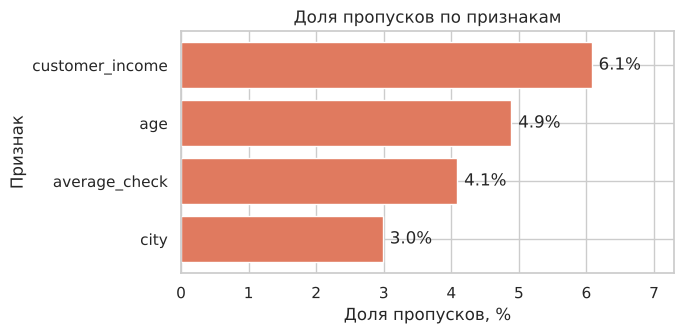

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(missing_nz.index[::-1], missing_nz["Доля, %"][::-1], color="#e07a5f")
for i, v in enumerate(missing_nz["Доля, %"][::-1]):
    ax.text(v + 0.1, i, f"{v:.1f}%", va="center")
ax.set_title("Доля пропусков по признакам")
ax.set_xlabel("Доля пропусков, %")
ax.set_ylabel("Признак")
ax.set_xlim(0, missing_nz["Доля, %"].max() * 1.2)
plt.tight_layout()
plt.show()

**Вывод по пропускам.** Пропуски есть в четырёх признаках: `customer_income` (61, 6.08%), `age` (49, 4.89%), `average_check` (41, 4.09%) и `city` (30, 2.99%). Это немного, и ни один признак не пропущен массово. Хотя бы один пропуск есть в 17% строк, поэтому удалять строки целиком нельзя: потеряем почти пятую часть данных.

- **Наиболее проблемный признак — `customer_income`.** Доход, вероятно, важный признак для сегментации, и в нём больше всего дыр. Заполнять его придётся с оценкой смещения (медиана внутри групп или модель).
- **`average_check` — пропуски не критичны.** Они восстанавливаются: средний чек ≈ `total_spent / orders_count`, а оба поля в этих строках заполнены (проверим в п. 3.3).
- **`age`.** Пропуски умеренные. Для кластеризации возраст нужен, поэтому либо импутация медианой по группам, либо отдельная категория «возраст неизвестен».
- **`city`.** Пропуски редкие, их безопасно заполнить значением `Неизвестно`: на числовые признаки это не влияет.
- Помимо явных пропусков, в данных есть **«скрытые» пропуски и заглушки** (например, значения на нижней границе). Они разобраны в п. 3.3.

## 3.2. Дубликаты

In [8]:
n_full_dup = df.duplicated().sum()
n_id_dup = df["customer_id"].duplicated().sum()
print(f"Полностью дублирующихся строк: {n_full_dup}")
print(f"Повторяющихся customer_id:      {n_id_dup}")

dup_ids = df.loc[df["customer_id"].duplicated(), "customer_id"]
display(df[df["customer_id"].isin(dup_ids)].sort_values(["customer_id"]))

# совпадают ли дубли по ID с дублями по всей строке?
conflict = df.drop_duplicates()["customer_id"].duplicated().sum()
print(f"\nПовторов customer_id с РАЗНЫМИ данными (конфликты): {conflict}")

Полностью дублирующихся строк: 3
Повторяющихся customer_id:      3


,customer_id,order_date,age,gender,city,product_category,payment_method,orders_count,average_check,customer_income,total_spent
50,C0051,2025-01-19 05:14:14.054054054,39.0,Мужской,Самара,Одежда,Наличные,4,2037.532280,NaN,9320.51
1000,C0051,2025-01-19 05:14:14.054054054,39.0,Мужской,Самара,Одежда,Наличные,4,2037.532280,NaN,9320.51
51,C0052,2025-01-19 13:58:55.135135135,31.0,Мужской,Новосибирск,Спорт,Карта,2,5440.054462,114188.357063,11523.20
1001,C0052,2025-01-19 13:58:55.135135135,31.0,Мужской,Новосибирск,Спорт,Карта,2,5440.054462,114188.357063,11523.20
52,C0053,2025-01-19 22:43:36.216216216,28.0,Мужской,Новосибирск,Дом,Карта,2,NaN,75743.723234,6628.40
1002,C0053,2025-01-19 22:43:36.216216216,28.0,Мужской,Новосибирск,Дом,Карта,2,NaN,75743.723234,6628.40



Повторов customer_id с РАЗНЫМИ данными (конфликты): 0


In [9]:
df = df.drop_duplicates().reset_index(drop=True)
print("Строк после удаления дубликатов:", len(df))
print("customer_id теперь уникален:", df["customer_id"].is_unique)

Строк после удаления дубликатов: 1000
customer_id теперь уникален: True


**Вывод.** Найдено 3 полностью одинаковых строки: клиенты `C0051`–`C0053` записаны дважды, второй раз в самом конце файла (строки 1001–1003). Конфликтов (один ID с разными данными) нет, то есть это именно технический дубль, например повторная загрузка фрагмента. Дубли удалены, `customer_id` стал уникальным. Если их оставить, три клиента посчитаются дважды, что исказит распределения и средние.

## 3.3. Типичные проблемы значений

### Числовые признаки

In [10]:
num_cols = ["age", "orders_count", "average_check", "customer_income", "total_spent"]
stats_tbl = df[num_cols].agg(["min", "max", "mean", "std"]).T
stats_tbl["медиана"] = df[num_cols].median()
display(stats_tbl.round(2))

,min,max,mean,std,медиана
age,-5.0,150.0,35.45,11.07,35.00
orders_count,1.0,10.0,3.97,1.60,4.00
average_check,500.0,85000.0,4314.15,3753.37,4139.85
customer_income,25000.0,250000.0,77339.14,36868.17,69622.77
total_spent,300.0,750000.0,17703.73,29425.95,14703.16


In [11]:
# Проверка правдоподобия по простым предметным правилам
rules = {
    "age < 14 или age > 100":          (df["age"] < 14) | (df["age"] > 100),
    "orders_count < 1":                 df["orders_count"] < 1,
    "average_check <= 0":               df["average_check"] <= 0,
    "total_spent <= 0":                 df["total_spent"] <= 0,
    "customer_income <= 0":             df["customer_income"] <= 0,
}
print(pd.Series({k: int(v.sum()) for k, v in rules.items()}, name="Нарушений").to_string())
print("\nНевозможные значения возраста:")
display(df.loc[rules["age < 14 или age > 100"], ["customer_id", "age"]])

age < 14 или age > 100    3
orders_count < 1          0
average_check <= 0        0
total_spent <= 0          0
customer_income <= 0      0

Невозможные значения возраста:


,customer_id,age
10,C0011,-5.0
20,C0021,0.0
30,C0031,150.0


In [12]:
# Нагромождение значений на границах (признак «заглушек» или обрезки)
floor_tbl = []
for c in ["total_spent", "average_check", "customer_income"]:
    mn, mx = df[c].min(), df[c].max()
    floor_tbl.append({
        "Признак": c,
        "Минимум": mn, "Строк с минимумом": int((df[c] == mn).sum()),
        "Следующее значение": round(df.loc[df[c] > mn, c].min(), 2),
        "Максимум": mx, "Строк с максимумом": int((df[c] == mx).sum()),
    })
display(pd.DataFrame(floor_tbl))

,Признак,Минимум,Строк с минимумом,Следующее значение,Максимум,Строк с максимумом
0,total_spent,300.0,13,387.21,750000.0,1
1,average_check,500.0,8,611.09,85000.0,1
2,customer_income,25000.0,11,25118.18,250000.0,2


In [13]:
# Логическая согласованность: total_spent ≈ orders_count * average_check ?
expected = df["orders_count"] * df["average_check"]
ratio = df["total_spent"] / expected
print(ratio.describe().round(3).to_string())

mismatch = (ratio < 0.5) | (ratio > 2)
print(f"\nСтрок, где total_spent отличается от orders_count*average_check более чем в 2 раза: {int(mismatch.sum())}")

cols = ["customer_id", "orders_count", "average_check", "total_spent"]
tmp = df.loc[mismatch, cols].assign(ожидалось=expected[mismatch].round(0), отношение=ratio[mismatch].round(2))
print("\nСамые «кричащие» несоответствия:")
display(tmp.sort_values("отношение", key=lambda s: np.log(s).abs(), ascending=False).head(8))

# можно ли восстановить пропущенный средний чек?
can_restore = df["average_check"].isna() & df["total_spent"].notna() & (df["orders_count"] > 0)
print(f"\nПропусков average_check, которые можно восстановить как total_spent/orders_count: {int(can_restore.sum())} из {int(df['average_check'].isna().sum())}")

count    960.000
mean       1.114
std        2.447
min        0.024
25%        0.883
50%        1.003
75%        1.112
max       57.059

Строк, где total_spent отличается от orders_count*average_check более чем в 2 раза: 50

Самые «кричащие» несоответствия:


,customer_id,orders_count,average_check,total_spent,ожидалось,отношение
400,C0401,3,2920.972476,500000.00,8763.0,57.06
500,C0501,4,3652.226076,750000.00,14609.0,51.34
300,C0301,4,85000.000000,8040.08,340000.0,0.02
200,C0201,4,60000.000000,7166.75,240000.0,0.03
156,C0157,2,2920.856752,300.00,5842.0,0.05
987,C0988,4,1310.317591,300.00,5241.0,0.06
543,C0544,4,1006.009423,300.00,4024.0,0.07
100,C0101,4,45000.000000,12455.78,180000.0,0.07



Пропусков average_check, которые можно восстановить как total_spent/orders_count: 40 из 40


**Выводы по числовым признакам.**

- **Возраст.** Есть три невозможных значения: `-5`, `0` и `150` (клиенты `C0011`, `C0021`, `C0031`). Остальные значения лежат в диапазоне 18–75 лет. Невозможные значения заменим на пропуск.
- **Нагромождение на границах.** В `total_spent` ровно 13 строк со значением `300.00`, в `average_check` — 8 со значением `500.00`, а в `customer_income` — 11 со значением `25000`. Для непрерывных величин с шумом так не бывает: вероятно, это обрезка снизу (минимальная сумма или «заглушка» вместо пропуска). Эти значения нельзя считать настоящими наблюдениями без проверки.
- **Аномальный средний чек.** Три значения `45000`, `60000` и `85000` (клиенты `C0101`, `C0201`, `C0301`) в 6–11 раз превышают 99-й процентиль (~7650). При этом их `total_spent` — всего 7–12 тысяч, так что чек физически не может быть таким.
- **Экстремальные суммы.** `total_spent = 500000` и `750000` (клиенты `C0401`, `C0501`) примерно в 50 раз больше, чем `orders_count × average_check`. Следующее по величине значение — около 54 тысяч.
- **Согласованность признаков.** В целом `total_spent ≈ orders_count × average_check` (медианное отношение ≈ 1.0), поэтому нарушения отчётливо видны: их около 50 строк. Это дополнительный признак ошибок и хороший кандидат для проверки в задаче поиска аномалий.
- Пропущенный `average_check` восстанавливается во всех случаях (40 из 40 после удаления дубликатов).

### Категориальные признаки

In [14]:
cat_cols = ["gender", "city", "product_category", "payment_method"]
for c in cat_cols:
    vals = df[c].dropna().unique().tolist()
    print(f"{c}: {df[c].nunique()} уникальных (с пропуском {df[c].nunique(dropna=False)})")
    print("   ", [repr(v) for v in sorted(vals)])

gender: 2 уникальных (с пропуском 2)
    ["'Женский'", "'Мужской'"]
city: 8 уникальных (с пропуском 9)
    ["' москва '", "'Екатеринбург'", "'Казань'", "'МОСКВА'", "'Москва'", "'Новосибирск'", "'Самара'", "'Санкт-Петербург'"]
product_category: 5 уникальных (с пропуском 5)
    ["'Дом'", "'Красота'", "'Одежда'", "'Спорт'", "'Электроника'"]
payment_method: 5 уникальных (с пропуском 5)
    ["' карта '", "'Карта'", "'Наличные'", "'Онлайн'", "'СБП'"]


Видим «грязные» категории: в `city` встречаются `' москва '` (с пробелами и строчными), `'МОСКВА'` и `'Москва'`, а в `payment_method` — `' карта '` и `'Карта'`. Это одни и те же значения, записанные по-разному. Для `pandas` это разные категории, и они раздробят группы. Нормализуем: убираем пробелы по краям, сравниваем без учёта регистра и берём самое частое написание как каноническое.

In [15]:
def normalize_categories(s: pd.Series) -> pd.Series:
    """Убирает лишние пробелы, сводит регистр: каноническое написание — самое частое."""
    stripped = s.str.strip()
    key = stripped.str.casefold()
    canon = stripped.groupby(key).agg(lambda x: x.value_counts().idxmax())
    return key.map(canon)

df_clean = df.copy()
before = {c: df_clean[c].nunique() for c in cat_cols}
for c in cat_cols:
    df_clean[c] = normalize_categories(df_clean[c])
after = {c: df_clean[c].nunique() for c in cat_cols}
display(pd.DataFrame({"Уникальных до": before, "Уникальных после": after}))
print(df_clean["city"].value_counts(dropna=False).to_string())
print()
print(df_clean["payment_method"].value_counts(dropna=False).to_string())

,Уникальных до,Уникальных после
gender,2,2
city,8,6
product_category,5,5
payment_method,5,4


city
Екатеринбург       173
Москва             169
Самара             167
Новосибирск        160
Казань             159
Санкт-Петербург    142
NaN                 30

payment_method
Онлайн      265
Наличные    257
Карта       243
СБП         235


In [16]:
# Невозможный возраст -> пропуск; затем компактные типы
df_clean["age"] = df_clean["age"].where(df_clean["age"].between(14, 100)).astype("Int64")
for c in cat_cols:
    df_clean[c] = df_clean[c].astype("category")
display(df_clean.dtypes.to_frame("Тип в df_clean"))
print("Пропусков в age после очистки:", int(df_clean["age"].isna().sum()), "(было 49, +3 невозможных значения)")

,Тип в df_clean
customer_id,str
order_date,datetime64[ns]
age,Int64
gender,category
city,category
product_category,category
payment_method,category
orders_count,int64
average_check,float64
customer_income,float64


Пропусков в age после очистки: 52 (было 49, +3 невозможных значения)


**Вывод по категориям.** После нормализации в `city` осталось 6 городов вместо 8 написаний: 8 строк с нестандартной записью Москвы (`' москва '`, `'МОСКВА'`) присоединились к основной категории (всего 169 клиентов). В `payment_method` стало 4 способа вместо 5: `' карта '` объединена с `Карта`. Пол и категория товара были чистыми. Далее работаем с `df_clean`; исходные данные `df_raw` не менялись.

## 3.4. Выбросы

Метод — межквартильный размах (IQR): выбросом считаем значение вне `[Q1 − 1.5·IQR; Q3 + 1.5·IQR]`. Для контроля сравним с правилом z-score (`|z| > 3`). Основной признак для визуализации — `total_spent`, остальные числовые признаки сведены в таблицу.

In [17]:
def iqr_bounds(s):
    s = s.dropna().astype(float)
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1, q3, iqr, q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for c in ["age", "orders_count", "average_check", "customer_income", "total_spent"]:
    s = df_clean[c].dropna().astype(float)
    q1, q3, iqr, lo, hi = iqr_bounds(s)
    z = (s - s.mean()) / s.std()
    rows.append({
        "Признак": c, "Q1": q1, "Q3": q3, "IQR": iqr,
        "Нижняя граница": lo, "Верхняя граница": hi,
        "Выбросов (IQR)": int(((s < lo) | (s > hi)).sum()),
        "Выбросов (|z|>3)": int((z.abs() > 3).sum()),
        "% (IQR)": round(((s < lo) | (s > hi)).mean() * 100, 2),
    })
display(pd.DataFrame(rows).round(1))

,Признак,Q1,Q3,IQR,Нижняя граница,Верхняя граница,Выбросов (IQR),Выбросов (|z|>3),% (IQR)
0,age,28.0,42.0,14.0,7.0,63.0,3,2,0.3
1,orders_count,3.0,5.0,2.0,0.0,8.0,4,4,0.4
2,average_check,3115.3,5191.5,2076.2,1.0,8305.8,5,3,0.5
3,customer_income,50488.4,96032.1,45543.7,-17827.1,164347.6,31,14,3.3
4,total_spent,9433.0,21896.8,12463.8,-9262.7,40592.5,22,2,2.2


In [18]:
s = df_clean["total_spent"]
q1, q3, iqr, lo, hi = iqr_bounds(s)
out_mask = (s < lo) | (s > hi)
print(f"total_spent: Q1={q1:.0f}, Q3={q3:.0f}, IQR={iqr:.0f}, границы [{lo:.0f}; {hi:.0f}]")
print(f"Выбросов: {int(out_mask.sum())} из {len(s)} ({out_mask.mean()*100:.1f}%)\n")
print("Самые большие значения:")
display(df_clean.loc[out_mask, ["customer_id", "orders_count", "average_check", "total_spent"]]
        .sort_values("total_spent", ascending=False).head(8))

total_spent: Q1=9433, Q3=21897, IQR=12464, границы [-9263; 40593]
Выбросов: 22 из 1000 (2.2%)

Самые большие значения:


,customer_id,orders_count,average_check,total_spent
500,C0501,4,3652.226076,750000.00
400,C0401,3,2920.972476,500000.00
374,C0375,9,6468.796053,54165.39
237,C0238,7,7506.279252,53015.17
692,C0693,10,5562.333190,52830.81
384,C0385,6,8491.704851,52574.25
230,C0231,7,7310.668024,51502.13
915,C0916,7,7132.066796,49389.11


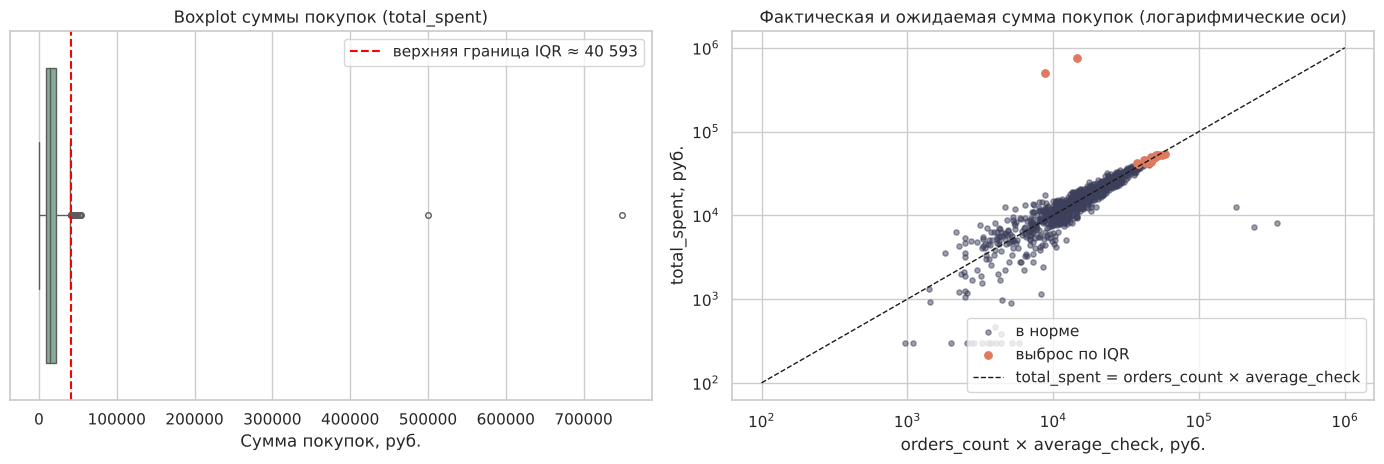

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

sns.boxplot(x=s, ax=axes[0], color="#81b29a", fliersize=4)
axes[0].axvline(hi, color="red", linestyle="--", label=f"верхняя граница IQR ≈ {hi:,.0f}".replace(",", " "))
axes[0].set_title("Boxplot суммы покупок (total_spent)")
axes[0].set_xlabel("Сумма покупок, руб.")
axes[0].legend()

exp = df_clean["orders_count"] * df_clean["average_check"]
ok = ~out_mask
axes[1].scatter(exp[ok], s[ok], s=14, alpha=0.5, color="#3d405b", label="в норме")
axes[1].scatter(exp[out_mask], s[out_mask], s=28, color="#e07a5f", label="выброс по IQR")
lim = [100, 1e6]
axes[1].plot(lim, lim, "k--", linewidth=1, label="total_spent = orders_count × average_check")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title("Фактическая и ожидаемая сумма покупок (логарифмические оси)")
axes[1].set_xlabel("orders_count × average_check, руб.")
axes[1].set_ylabel("total_spent, руб.")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

**Вывод по выбросам.** По правилу IQR в `total_spent` выбросами названо 22 наблюдения (2.2%), по z-score — всего 2: правило 3σ ослеплено двумя экстремальными значениями, раздувшими стандартное отклонение, поэтому IQR здесь надёжнее. Выбросы бывают двух видов:

- **Ошибки (2 строки).** `500000` и `750000` лежат далеко от диагонали на правом графике: они в ~50 раз выше, чем `orders_count × average_check`. Это почти наверняка ошибки данных, их нельзя использовать в обучении без проверки.
- **Реальный «тяжёлый хвост» (20 строк).** Значения 41–54 тысячи лежат вдоль диагонали, то есть согласуются с числом заказов и чеком. Это настоящие крупные клиенты (в задаче сегментации они как раз интересны), удалять их не нужно.

Остальные признаки: у `average_check` 5 выбросов — три ошибочных чека 45–85 тысяч (см. п. 3.3) и два чека около 8.5 тысяч, лишь слегка выше границы; в `customer_income` 31 значение выше ≈ 164 тысяч — вероятно, настоящие высокие доходы (хвост идёт плавно до 250 тысяч); в `age` три значения старше 63 лет — правдоподобные клиенты старшего возраста, их оставляем.

# 4. Разведочный анализ

Для визуализаций берём очищенные данные `df_clean` и дополнительно исключаем заведомо ошибочные значения, найденные в аудите: 2 строки с `total_spent > 100 000` и 3 нереалистичных значения `average_check ≥ 20 000` (последние заменяем на пропуск). В исходных данных эти записи остаются, решение отражено в плане улучшения качества.

In [20]:
df_eda = df_clean[df_clean["total_spent"] <= 100_000].copy()
df_eda.loc[df_eda["average_check"] >= 20_000, "average_check"] = np.nan
df_eda["age"] = df_eda["age"].astype("float")
df_eda["month"] = df_eda["order_date"].dt.month
print("Строк для EDA:", len(df_eda))

Строк для EDA: 998


### 4.1. Распределение числового признака — сумма покупок

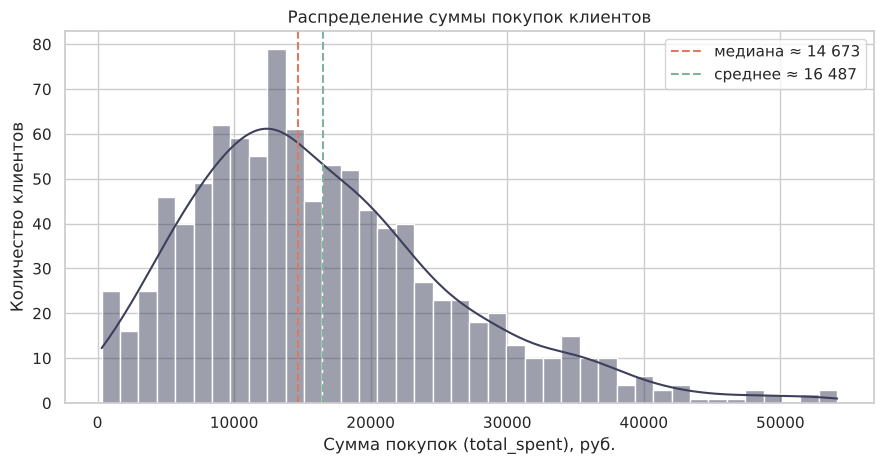

Асимметрия: 0.91


In [21]:
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.histplot(df_eda["total_spent"], bins=40, kde=True, color="#3d405b", ax=ax)
med, mean = df_eda["total_spent"].median(), df_eda["total_spent"].mean()
ax.axvline(med, color="#e07a5f", linestyle="--", label=f"медиана ≈ {med:,.0f}".replace(",", " "))
ax.axvline(mean, color="#81b29a", linestyle="--", label=f"среднее ≈ {mean:,.0f}".replace(",", " "))
ax.set_title("Распределение суммы покупок клиентов")
ax.set_xlabel("Сумма покупок (total_spent), руб.")
ax.set_ylabel("Количество клиентов")
ax.legend()
plt.tight_layout()
plt.show()
print("Асимметрия:", round(df_eda["total_spent"].skew(), 2))

**Что видно.** Распределение одномодальное и с правым хвостом: пик около 12–15 тысяч, половина клиентов тратит от 9 до 22 тысяч, а единицы — 40–54 тысячи. Среднее выше медианы, асимметрия положительная (≈ 0.9). В первом интервале у левого края заметен небольшой всплеск — это значения `300`.

**Гипотезы.** Распределение похоже на логнормальное, и для регрессии `total_spent` имеет смысл логарифмировать. Среднее хуже подходит как «типичное» значение, чем медиана.

**Вопросы.** Откуда берётся всплеск на 300 рублях: минимальный платёж или обрезка при выгрузке? Чем отличаются клиенты из правого хвоста?

### 4.2. Распределение категориальных признаков

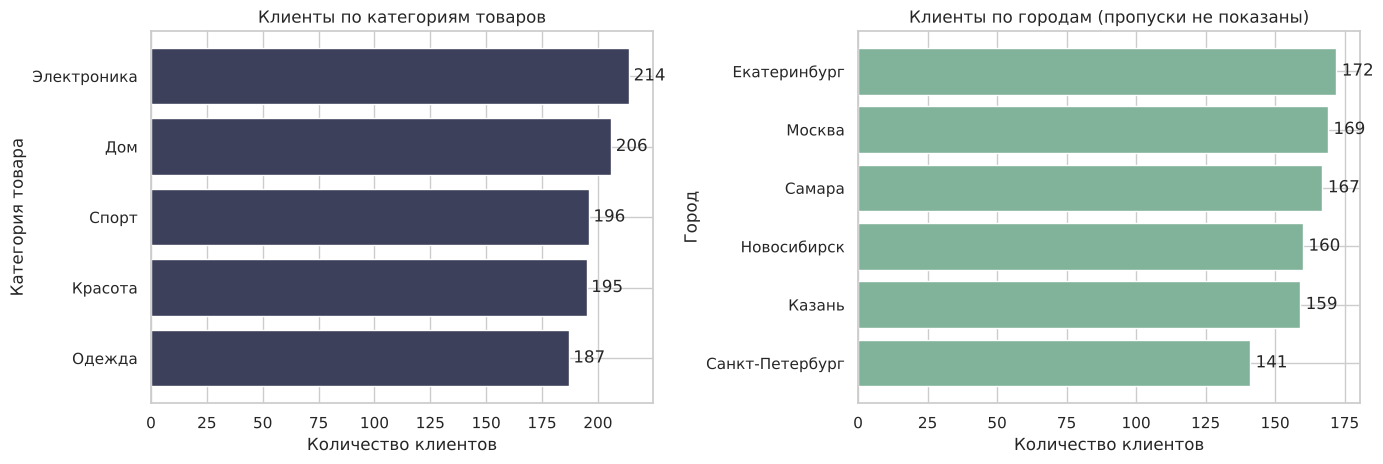

product_category
Электроника    0.214
Дом            0.206
Спорт          0.196
Красота        0.195
Одежда         0.187


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

pc = df_eda["product_category"].value_counts()
axes[0].barh(pc.index[::-1].astype(str), pc.values[::-1], color="#3d405b")
for i, v in enumerate(pc.values[::-1]):
    axes[0].text(v + 2, i, str(v), va="center")
axes[0].set_title("Клиенты по категориям товаров")
axes[0].set_xlabel("Количество клиентов"); axes[0].set_ylabel("Категория товара")

ct = df_eda["city"].value_counts()
axes[1].barh(ct.index[::-1].astype(str), ct.values[::-1], color="#81b29a")
for i, v in enumerate(ct.values[::-1]):
    axes[1].text(v + 2, i, str(v), va="center")
axes[1].set_title("Клиенты по городам (пропуски не показаны)")
axes[1].set_xlabel("Количество клиентов"); axes[1].set_ylabel("Город")
plt.tight_layout()
plt.show()
print(df_eda["product_category"].value_counts(normalize=True).round(3).to_string())

**Что видно.** Категории товаров представлены почти поровну (по 19–21%), а города — примерно по 14–17%: ни одна категория и ни один город не доминируют. После нормализации Москва стала обычным городом, а не «трёхголовой» категорией.

**Гипотезы.** Такая ровность для реальных данных нетипична (обычно один-два города/категории доминируют), что подтверждает синтетическое происхождение датасета. Результаты, полученные на этих данных, нельзя переносить на реальный магазин без проверки.

**Вопросы.** Строится ли выборка по квотам? Один клиент — одна категория: что делать с теми, кто покупает в нескольких категориях?

### 4.3. Зависимость: число заказов и сумма покупок

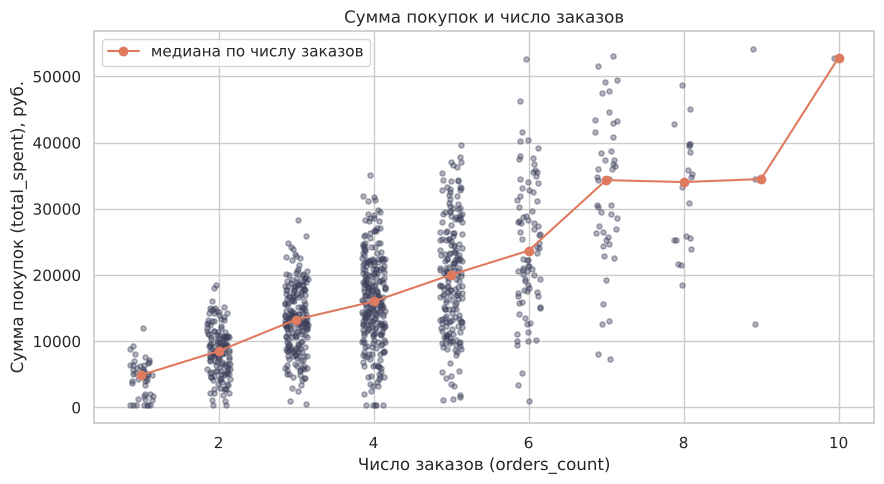

Корреляция Спирмена: 0.64


In [23]:
fig, ax = plt.subplots(figsize=(9, 5))
rng = np.random.default_rng(42)
x = df_eda["orders_count"] + rng.uniform(-0.15, 0.15, len(df_eda))   # небольшой «джиттер»
ax.scatter(x, df_eda["total_spent"], s=14, alpha=0.4, color="#3d405b")
med_by_n = df_eda.groupby("orders_count")["total_spent"].median()
ax.plot(med_by_n.index, med_by_n.values, "o-", color="#e07a5f", label="медиана по числу заказов")
ax.set_title("Сумма покупок и число заказов")
ax.set_xlabel("Число заказов (orders_count)")
ax.set_ylabel("Сумма покупок (total_spent), руб.")
ax.legend()
plt.tight_layout()
plt.show()
rho = df_eda[["orders_count", "total_spent"]].corr(method="spearman").iloc[0, 1]
print(f"Корреляция Спирмена: {rho:.2f}")

**Что видно.** Чем больше заказов, тем выше сумма покупок: медиана растёт почти линейно (около 5 тысяч при одном заказе, 16 при четырёх, 34 при семи-девяти), но разброс при каждом числе заказов заметный. Корреляция Спирмена ≈ 0.64. При 9–10 заказах клиентов очень мало (4 человека), поэтому там медиане доверять нельзя.

**Гипотезы.** Сумма — это примерно число заказов × средний чек, а разброс создаёт чек: клиенты с одинаковым числом заказов различаются именно размером чека. Значит, для сегментации важны оба признака, а не только частота.

**Вопросы.** Если `total_spent` вычисляется из других столбцов, нужно ли предсказывать его в задаче регрессии (утечка цели)?

### 4.4. Зависимость: категория товара и сумма покупок

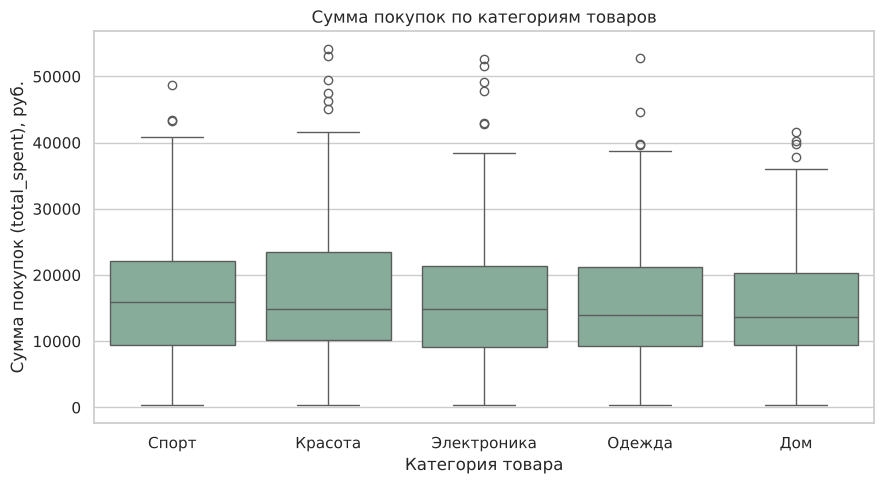

product_category
Спорт          15891.0
Красота        14927.0
Электроника    14896.0
Одежда         13954.0
Дом            13692.0


In [24]:
order = df_eda.groupby("product_category", observed=True)["total_spent"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df_eda, x="product_category", y="total_spent", order=order, color="#81b29a", ax=ax)
ax.set_title("Сумма покупок по категориям товаров")
ax.set_xlabel("Категория товара")
ax.set_ylabel("Сумма покупок (total_spent), руб.")
plt.tight_layout()
plt.show()
print(df_eda.groupby("product_category", observed=True)["total_spent"].median().round(0).sort_values(ascending=False).to_string())

**Что видно.** Медианы по категориям близки (от ≈ 13.7 тысяч у «Дома» до ≈ 15.9 у «Спорта»), «ящики» сильно перекрываются.

**Гипотезы.** Категория товара почти не объясняет сумму покупок: различия небольшие и могут быть случайными (проверить тестом Краскела–Уоллиса).

**Вопросы.** Различаются ли категории по среднему чеку, а не по сумме? Не нужно ли смотреть на сочетание «категория × город»?

### 4.5. Корреляции числовых признаков

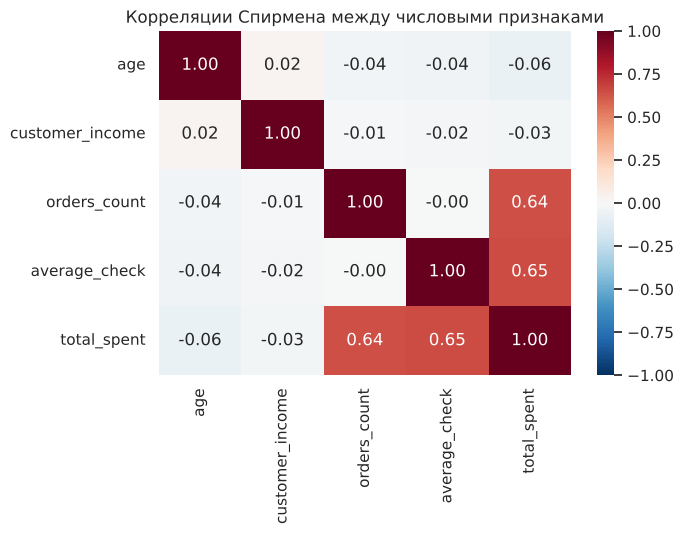

In [25]:
num_eda = ["age", "customer_income", "orders_count", "average_check", "total_spent"]
corr = df_eda[num_eda].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Корреляции Спирмена между числовыми признаками")
plt.tight_layout()
plt.show()

**Что видно.** Сумма покупок связана только с числом заказов и средним чеком (≈ 0.6 с каждым). Возраст и доход практически не коррелируют ни с чем (|ρ| < 0.1), даже друг с другом.

**Гипотезы.** Демографические признаки в этом датасете почти не несут информации о поведении клиента, поэтому на них не стоит рассчитывать при прогнозе `total_spent`; для сегментации они пригодны как описательные.

**Вопросы.** Нет ли нелинейных зависимостей, которые не ловит корреляция (например, доход — «ступенчатый» эффект)?

### 4.6. Динамика заказов по месяцам

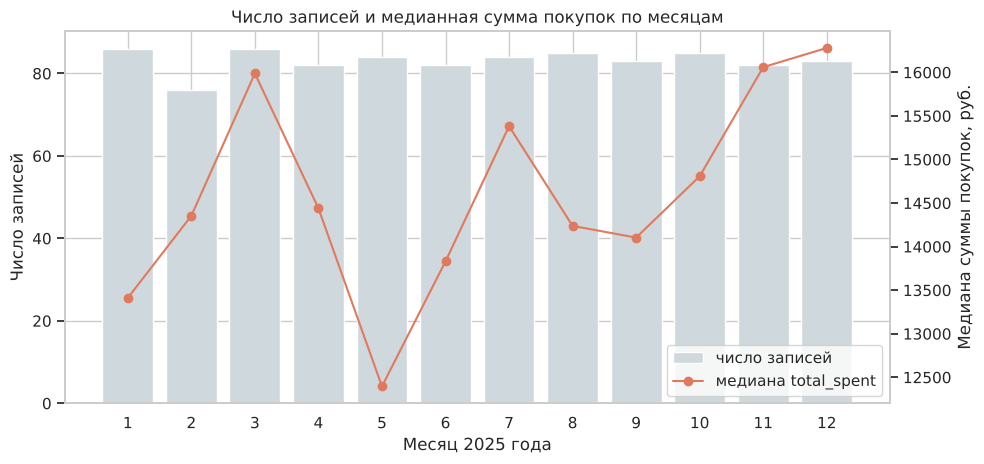

In [26]:
monthly = df_eda.groupby("month").agg(клиентов=("customer_id", "count"), медиана=("total_spent", "median"))
fig, ax1 = plt.subplots(figsize=(10, 4.8))
ax1.bar(monthly.index, monthly["клиентов"], color="#cfd8dc", label="число записей")
ax1.set_xlabel("Месяц 2025 года"); ax1.set_ylabel("Число записей")
ax1.set_xticks(range(1, 13))
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["медиана"], "o-", color="#e07a5f", label="медиана total_spent")
ax2.set_ylabel("Медиана суммы покупок, руб."); ax2.grid(False)
ax1.set_title("Число записей и медианная сумма покупок по месяцам")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower right")
plt.tight_layout()
plt.show()

**Что видно.** Записей в каждом месяце примерно поровну, то есть даты заказов распределены по году равномерно (даже слишком: шаг между соседними датами почти постоянен). Медианная сумма колеблется между месяцами без чёткой сезонности.

**Гипотезы.** `order_date` сгенерирована как равномерная сетка и вряд ли отражает реальную сезонность. Различия медиан по месяцам вероятнее всего шум.

**Вопросы.** Что означает `order_date` для клиента с несколькими заказами — дату первого, последнего заказа или регистрации? Без ответа нельзя строить признаки «давность» и «частота».

# Часть 2. Продолжение лабораторной работы №1

Задания 1–8 выполняются на том же датасете `online_store_customers.csv` и используют данные, подготовленные выше: `df_clean` (после удаления дубликатов и нормализации категорий) и `df_eda` (без заведомо ошибочных значений, см. раздел 4).

# 5. Типы признаков и шкалы измерения

## Задание 1

### 1.1. Шкалы измерения признаков

| Признак | Шкала | Обоснование |
| :--- | :--- | :--- |
| `customer_id` | номинальная | метка клиента; числовая часть кода не имеет математического смысла |
| `order_date` | интервальная | время откладывается от условной точки отсчёта: разности имеют смысл, отношения («в 2 раза позже») — нет |
| `age` | отношений | есть естественный ноль, возраст 40 в два раза больше возраста 20 |
| `gender` | номинальная | две категории без порядка |
| `city` | номинальная | категории без порядка |
| `product_category` | номинальная | категории без порядка |
| `payment_method` | номинальная | способы оплаты не упорядочены |
| `orders_count` | абсолютная | это счётчик: единица измерения естественна (один заказ), преобразования масштаба недопустимы |
| `average_check` | отношений | денежная величина с естественным нулём |
| `customer_income` | отношений | денежная величина с естественным нулём |
| `total_spent` | отношений | денежная величина с естественным нулём |

Порядковых признаков в датасете нет. Они появились бы, если бы доход разбили на интервалы («низкий / средний / высокий»).

### 1.2. Два признака с разными шкалами

Берём **`product_category`** (номинальная шкала) и **`total_spent`** (шкала отношений). Для сравнения добавим `order_date` (интервальная шкала). Посмотрим, что реально посчитает `pandas`, и обсудим, что из этого осмысленно.

In [27]:
cat = df_eda["product_category"]
x = df_eda["total_spent"]

# Произвольные числовые кодировки категорий: алфавитная и по частоте
codes_alpha = cat.cat.codes
freq_order = cat.value_counts().index.tolist()
codes_freq = cat.astype(str).map({v: i for i, v in enumerate(freq_order)})

rows = [
    ("product_category", "мода",                          cat.mode().iloc[0],                       "корректно"),
    ("product_category", "среднее кодов (алфавит)",       round(codes_alpha.mean(), 3),             "неверно: код зависит от порядка кодирования"),
    ("product_category", "среднее кодов (по частоте)",    round(codes_freq.mean(), 3),              "неверно: другая кодировка даёт другое число"),
    ("product_category", "медиана кодов (алфавит)",       float(codes_alpha.median()),              "неверно: «середина» несуществующего порядка"),
    ("total_spent",      "среднее",                       round(x.mean(), 1),                       "корректно (чувствительно к хвосту)"),
    ("total_spent",      "медиана",                       round(x.median(), 1),                     "корректно (устойчива к выбросам)"),
    ("total_spent",      "мода",                          x.mode().iloc[0],                         "считается, но бессмысленна для непрерывной величины"),
    ("order_date",       "среднее",                       df_eda["order_date"].mean().date(),       "допустимо для интервальной шкалы (середина периода)"),
    ("order_date",       "отношение дат",                 "—",                                      "неверно: «дата в 2 раза позже» не определена"),
]
display(pd.DataFrame(rows, columns=["Признак", "Агрегат", "Что посчитал pandas", "Методологическая оценка"]))

print("Доля женщин (среднее индикатора 0/1):", round((df_eda["gender"] == "Женский").mean(), 3))
print("Сколько раз встречается мода total_spent:", int((x == x.mode().iloc[0]).sum()), "из", len(x))

,Признак,Агрегат,Что посчитал pandas,Методологическая оценка
0,product_category,мода,Электроника,корректно
1,product_category,среднее кодов (алфавит),2.017,неверно: код зависит от порядка кодирования
2,product_category,среднее кодов (по частоте),1.935,неверно: другая кодировка даёт другое число
3,product_category,медиана кодов (алфавит),2.0,неверно: «середина» несуществующего порядка
4,total_spent,среднее,16486.7,корректно (чувствительно к хвосту)
5,total_spent,медиана,14673.0,корректно (устойчива к выбросам)
6,total_spent,мода,300.0,"считается, но бессмысленна для непрерывной величины"
7,order_date,среднее,2025-07-02,допустимо для интервальной шкалы (середина периода)
8,order_date,отношение дат,—,неверно: «дата в 2 раза позже» не определена


Доля женщин (среднее индикатора 0/1): 0.511
Сколько раз встречается мода total_spent: 13 из 998


**Выводы.**

- **`product_category` (номинальная).** Имеет смысл только **мода** (самая частая категория) и частоты. Среднее и медиана кодов `pandas` считает без ошибок (категории превращаются в числа 0, 1, 2…), но результат зависит от произвольного порядка кодов: при алфавитной кодировке и при кодировке по частоте средние получаются разными. Значит, число не описывает данные, а лишь отражает способ кодирования.
- **`total_spent` (шкала отношений).** Корректны все три «центра», но **среднее** чувствительно к хвосту, а **мода** для непрерывной величины почти бессмысленна: единственное значение с повторами здесь — `300`, то есть «заглушка», найденная при аудите, а не «типичный клиент». Кроме того, допустимы отношения («в 2 раза больше») и логарифмирование.
- **`order_date` (интервальная).** Допустимы разности и сдвиги (середина периода, длительность), а отношения дат не определены.
- **Особый случай.** Среднее бинарного индикатора (`gender == 'Женский'`) — это доля, и такое «среднее» корректно. Но это доля категории, а не среднее самой категориальной переменной.

**Общий вывод.** Корректные агрегаты для номинальной шкалы — мода и частоты, для интервальной — ещё медиана, среднее и разности, для шкалы отношений — всё перечисленное плюс отношения. `pandas` посчитает любой агрегат над числовыми кодами, поэтому выбор агрегата — решение аналитика, а не библиотеки.

# 6. Пропуски и их природа (MCAR / MAR / MNAR)

## Задание 2. Диагностика типа пропусков

Выбираем **`customer_income`**: это признак с наибольшей долей пропусков (6%), и он важен для сегментации.

### 2.1. Три гипотезы

| Гипотеза | Формулировка для `customer_income` | Какие наблюдаемые признаки могут подтвердить или опровергнуть |
| :--- | :--- | :--- |
| **MCAR** (полностью случайно) | Доход не указан случайно (сбой выгрузки, клиент пропустил поле). Вероятность пропуска не зависит ни от дохода, ни от других признаков | любой наблюдаемый признак: при MCAR распределения признаков у клиентов «с доходом» и «без дохода» не отличаются |
| **MAR** (случайно при условии наблюдаемого) | Вероятность пропуска зависит от других заполненных признаков, например от возраста, города, способа оплаты или категории товара | `age`, `city`, `payment_method`, `product_category`, `gender`, `orders_count`, `average_check`, `total_spent`, месяц заказа: значимые различия указывают на MAR |
| **MNAR** (не случайно) | Вероятность пропуска зависит от самого значения дохода (например, клиенты с высоким или низким доходом не хотят его указывать) | напрямую не проверяется: значение отсутствует. Можно лишь косвенно оценить чувствительность выводов и поискать признаки обрезки значений |

### 2.2. Проверки (с реализацией)

**Проверка 1 (MCAR против MAR).** Для каждого наблюдаемого признака сравниваем группы «доход указан» и «доход пропущен»: критерий Манна–Уитни для числовых (с мерой эффекта AUC) и хи-квадрат для категориальных (с мерой эффекта V Крамера). Так как проверок несколько, применяем поправку Бонферрони.

In [28]:
miss = df_clean["customer_income"].isna()
print(f"Доход пропущен у {int(miss.sum())} из {len(df_clean)} клиентов ({miss.mean()*100:.1f}%)\n")

rows = []
for c in ["age", "orders_count", "average_check", "total_spent"]:
    a = df_clean.loc[~miss, c].dropna().astype(float)
    b = df_clean.loc[miss, c].dropna().astype(float)
    u, p = stats.mannwhitneyu(a, b)
    rows.append({"Признак": c, "Тест": "Манн–Уитни", "p": p, "Мера эффекта": f"AUC = {u/(len(a)*len(b)):.2f}"})

tmp = df_clean.assign(month=df_clean["order_date"].dt.month)
for c in ["gender", "city", "product_category", "payment_method", "month"]:
    tbl = pd.crosstab(tmp[c], miss)
    chi2, p, dof, _ = stats.chi2_contingency(tbl)
    v = np.sqrt(chi2 / (tbl.values.sum() * (min(tbl.shape) - 1)))
    rows.append({"Признак": c, "Тест": "хи-квадрат", "p": p, "Мера эффекта": f"V = {v:.2f}"})

# связь с пропусками в других столбцах
for c in ["age", "average_check", "city"]:
    tbl = pd.crosstab(df_clean[c].isna(), miss)
    p = stats.fisher_exact(tbl)[1]
    rows.append({"Признак": f"пропуск в {c}", "Тест": "точный Фишера", "p": p, "Мера эффекта": "—"})

res = pd.DataFrame(rows)
m = len(res)
res["p (Бонферрони)"] = (res["p"] * m).clip(upper=1)
res["Значимо при α=0.05"] = np.where(res["p (Бонферрони)"] < 0.05, "да", "нет")
res["p"] = res["p"].round(3); res["p (Бонферрони)"] = res["p (Бонферрони)"].round(3)
display(res)
print(f"\nПроверок: {m}. Минимальное p без поправки: {res['p'].min()}")

Доход пропущен у 60 из 1000 клиентов (6.0%)



,Признак,Тест,p,Мера эффекта,p (Бонферрони),Значимо при α=0.05
0,age,Манн–Уитни,0.131,AUC = 0.56,1.0,нет
1,orders_count,Манн–Уитни,0.731,AUC = 0.49,1.0,нет
2,average_check,Манн–Уитни,0.131,AUC = 0.56,1.0,нет
3,total_spent,Манн–Уитни,0.271,AUC = 0.54,1.0,нет
4,gender,хи-квадрат,0.306,V = 0.03,1.0,нет
5,city,хи-квадрат,0.657,V = 0.06,1.0,нет
6,product_category,хи-квадрат,0.814,V = 0.04,1.0,нет
7,payment_method,хи-квадрат,0.803,V = 0.03,1.0,нет
8,month,хи-квадрат,0.388,V = 0.11,1.0,нет
9,пропуск в age,точный Фишера,0.764,—,1.0,нет



Проверок: 12. Минимальное p без поправки: 0.131


**Проверка 2 (MNAR, косвенная).** Если пропуск зависит от самого дохода, то среднее по наблюдаемым значениям смещено. Оценим, **насколько** могло бы сместиться среднее при крайних сценариях: все пропущенные значения равны 10-му или 90-му перцентилю наблюдаемого дохода. Заодно проверим, можно ли вообще предсказать доход по другим признакам (если нет, то и MAR-заполнение мало что даёт).

In [29]:
obs = df_clean["customer_income"].dropna()
n_all, k = len(df_clean), int(miss.sum())

def mean_with(fill):
    return (obs.sum() + k * fill) / n_all

scen = pd.DataFrame({
    "Сценарий": ["пропуски похожи на наблюдаемых (MCAR/MAR)", "все пропуски = 10-й перцентиль (MNAR: «бедные» скрывают)", "все пропуски = 90-й перцентиль (MNAR: «богатые» скрывают)"],
    "Среднее доход": [obs.mean(), mean_with(obs.quantile(0.10)), mean_with(obs.quantile(0.90))],
})
scen["Отличие от наблюдаемого среднего, %"] = ((scen["Среднее доход"] / obs.mean() - 1) * 100).round(1)
scen["Среднее доход"] = scen["Среднее доход"].round(0)
display(scen)

print("\nСвязь наблюдаемого дохода с другими числовыми признаками (корреляция Спирмена):")
print(df_clean[["customer_income", "age", "orders_count", "average_check", "total_spent"]].astype(float)
      .corr(method="spearman")["customer_income"].drop("customer_income").round(3).to_string())
print("\nЗначений дохода ровно на нижней границе 25000:", int((obs == 25000).sum()), "(возможна обрезка снизу)")

,Сценарий,Среднее доход,"Отличие от наблюдаемого среднего, %"
0,пропуски похожи на наблюдаемых (MCAR/MAR),77339.0,0.0
1,все пропуски = 10-й перцентиль (MNAR: «бедные» скрывают),74987.0,-3.0
2,все пропуски = 90-й перцентиль (MNAR: «богатые» скрывают),80261.0,3.8



Связь наблюдаемого дохода с другими числовыми признаками (корреляция Спирмена):
age              0.025
orders_count    -0.013
average_check   -0.020
total_spent     -0.028

Значений дохода ровно на нижней границе 25000: 11 (возможна обрезка снизу)


### 2.3. Вывод по гипотезам

- **MCAR — не опровергнута.** Ни один из проверенных признаков не отличается у клиентов с пропущенным и указанным доходом: после поправки Бонферрони значимых различий нет. Это согласуется с MCAR, но не доказывает его: пропусков всего 60, и тест может не заметить слабую зависимость.
- **MAR — не подтверждена.** Нет признака, который объяснял бы пропуск. Кроме того, доход почти не коррелирует с остальными числовыми признаками, поэтому предсказать его (а значит, и «умно» заполнить) по другим столбцам нельзя.
- **MNAR — проверить принципиально нельзя**, но влияние ограничено: даже в крайних сценариях среднее дохода меняется всего на −3.0% и +3.8%, потому что пропусков немного. Для задач сегментации это приемлемо.
- **Практическое решение.** Заполнять пропуски медианой (или медианой по группам) и сохранять индикатор пропуска. Отдельно нужно разобраться с 11 значениями ровно `25000`: это может быть «заглушка» вместо пропуска.

## Задание 3. Индикатор пропуска как источник информации

### 3.1. Когда сам факт пропуска несёт информацию
Факт пропуска информативен, если он связан с интересующей нас переменной или целью, то есть пропуск не случаен (MAR или MNAR). Например, клиент не указал адрес именно потому, что заказал самовывоз. Тогда бинарный индикатор `is_missing` становится самостоятельным признаком. При MCAR индикатор ничего не несёт: он не связан ни с чем, кроме случайности.

### 3.2. Почему значимость индикатора — сигнал о неудачной импутации
Хорошая импутация заменяет пропуск значением, которое «похоже» на настоящее, с учётом других признаков. Если после такого заполнения индикатор по-прежнему значимо влияет на цель, то заполненное значение не передало информацию о группе клиентов с пропусками. Возможные причины:

1. **Грубое заполнение** (например, одной глобальной медианой): оно стирает различия между группами, и индикатор их «возвращает».
2. **Нарушенная гипотеза о механизме пропусков** (MNAR): значение систематически отличается от заполненного, а модель компенсирует это индикатором.

То есть значимый индикатор говорит, что импутация потеряла структуру данных. Он не отменяет необходимости улучшить заполнение, и он же признак возможной утечки, если пропуск возникает уже после известной цели.

### 3.3. Проверка на наших данных
Для каждого столбца с пропусками проверим, связан ли индикатор пропуска с целевой величиной `total_spent`.

In [30]:
rows = []
for c in ["customer_income", "age", "average_check", "city"]:
    m_ = df_clean[c].isna()
    a = df_clean.loc[~m_, "total_spent"]
    b = df_clean.loc[m_, "total_spent"]
    u, p = stats.mannwhitneyu(a, b)
    rows.append({"Индикатор": f"{c}_is_null", "Пропусков": int(m_.sum()),
                 "Медиана total_spent (значение есть)": round(a.median()), "Медиана total_spent (пропуск)": round(b.median()),
                 "AUC": round(u / (len(a) * len(b)), 2), "p": round(p, 3)})
display(pd.DataFrame(rows))

,Индикатор,Пропусков,Медиана total_spent (значение есть),Медиана total_spent (пропуск),AUC,p
0,customer_income_is_null,60,14899,13188,0.54,0.271
1,age_is_null,52,14662,15034,0.48,0.667
2,average_check_is_null,40,14703,14534,0.47,0.591
3,city_is_null,30,14649,16821,0.47,0.599


**Вывод.** Ни один из индикаторов не связан с суммой покупок: AUC около 0.5, p > 0.05. В этом датасете пропуски похожи на случайные, поэтому индикаторы **бесполезны**: они добавили бы лишний шум.

### 3.4. Примеры

- **Полезен — `city` в реальном магазине (гипотетический пример).** Если адрес не указывают при самовывозе или оплате наличными, факт пропуска описывает способ получения заказа и может влиять на сумму и частоту покупок. В нашем датасете такой связи нет, но в реальных данных она типична.
- **Бесполезен — `customer_income` в нашем датасете.** Пропуски случайны (проверка выше), индикатор не связан ни с одним признаком и целью.
- **Опасен — `average_check` (пропуск восстановим из `total_spent / orders_count`).** Если индикатор пропуска чека использовать вместе с таким восстановлением, он начинает кодировать способ получения признака, а не свойство клиента. В реальной системе, где чек не считается из других столбцов (или считается по-другому), эта зависимость исчезнет, и модель потеряет качество. Ещё опаснее индикатор признака, который заполняется уже после целевого события: он становится утечкой цели.

# 7. Выбросы

## Задание 4. Выброс — ошибка или сигнал?

Берём числовой признак **`total_spent`** и один найденный выброс: клиент **`C0501`**, у которого сумма покупок равна 750 000 руб.

In [31]:
row = df_clean.loc[df_clean["customer_id"] == "C0501", ["customer_id", "age", "city", "product_category", "payment_method",
                                                         "orders_count", "average_check", "total_spent"]]
display(row)
r_ = row.iloc[0]
print(f"orders_count × average_check = {r_['orders_count'] * r_['average_check']:,.0f} руб.".replace(",", " "))
print(f"total_spent / (orders_count × average_check) = {r_['total_spent'] / (r_['orders_count'] * r_['average_check']):.1f}")
print(f"Медиана total_spent по датасету: {df_clean['total_spent'].median():,.0f} руб.".replace(",", " "))
print(f"Во сколько раз выброс больше 99-го перцентиля остальных: "
      f"{r_['total_spent'] / df_clean.loc[df_clean['total_spent'] < 100000, 'total_spent'].quantile(0.99):.1f}")

,customer_id,age,city,product_category,payment_method,orders_count,average_check,total_spent
500,C0501,45,Екатеринбург,Электроника,СБП,4,3652.226076,750000.0


orders_count × average_check = 14 609 руб.
total_spent / (orders_count × average_check) = 51.3
Медиана total_spent по датасету: 14 703 руб.
Во сколько раз выброс больше 99-го перцентиля остальных: 16.2


### 4.1. Какие реальные причины могут объяснить это значение

1. **Ошибка ввода или единиц измерения.** Лишние нули при ручном вводе, сумма в копейках вместо рублей и т. п. Отношение к ожидаемой сумме (≈ 51) не равно степени десяти, но ошибки могут быть сложнее.
2. **Ошибка учёта.** Суммирование заказов нескольких клиентов или тестовые заказы под одним аккаунтом.
3. **Реальная крупная закупка.** Оптовый или корпоративный заказ (например, оформление на «клиента-магазин»). Но тогда странно, что `orders_count` и `average_check` остались «обычными»: при реальной закупке чек был бы тоже большим.
4. **Мошенничество или тест платёжной системы**, если речь о нетипичной операции.

Согласованность с другими столбцами (сумма в 51 раз больше, чем следует из числа заказов и чека) указывает, что наиболее вероятна именно **ошибка данных**, а не реальный клиент.

### 4.2. Что хуже для анализа
Сравним три подхода количественно. Чтобы выделить эффект именно этого выброса, из сравнения исключён второй экстремум (`C0401`, 500 000).

In [32]:
base = df_clean[df_clean["customer_id"] != "C0401"].copy()
oc = base["orders_count"].astype(float)

def metrics(y, label):
    slope = np.polyfit(oc, y, 1)[0]
    return {"Подход": label, "Среднее": y.mean(), "Ст. откл.": y.std(),
            "Асимметрия": y.skew(), "Корреляция Пирсона с orders_count": np.corrcoef(oc, y)[0, 1], "Наклон (руб. за заказ)": slope}

y_keep = base["total_spent"].astype(float)
mask_keep = base["customer_id"] != "C0501"
y_del = y_keep[mask_keep]
cap = y_keep.quantile(0.99)
y_win = y_keep.clip(upper=cap)

rows = [metrics(y_keep, "оставить без изменений")]
# удаление: считаем по оставшимся строкам
slope_del = np.polyfit(oc[mask_keep], y_del, 1)[0]
rows.append({"Подход": "удалить выброс", "Среднее": y_del.mean(), "Ст. откл.": y_del.std(), "Асимметрия": y_del.skew(),
             "Корреляция Пирсона с orders_count": np.corrcoef(oc[mask_keep], y_del)[0, 1], "Наклон (руб. за заказ)": slope_del})
rows.append(metrics(y_win, f"винзоризовать до 99-го перцентиля ({cap:,.0f})".replace(",", " ")))
y_log = np.log(y_keep)
rows.append({"Подход": "логарифм (значения в лог-шкале)", "Среднее": y_log.mean(), "Ст. откл.": y_log.std(), "Асимметрия": y_log.skew(),
             "Корреляция Пирсона с orders_count": np.corrcoef(oc, y_log)[0, 1], "Наклон (руб. за заказ)": np.nan})
display(pd.DataFrame(rows).round(2))

,Подход,Среднее,Ст. откл.,Асимметрия,Корреляция Пирсона с orders_count,Наклон (руб. за заказ)
0,оставить без изменений,17220.95,25168.33,24.82,0.26,4126.35
1,удалить выброс,16486.70,9744.73,0.91,0.68,4117.17
2,винзоризовать до 99-го перцентиля (47 461),16485.72,9679.20,0.84,0.67,4069.65
3,логарифм (значения в лог-шкале),9.48,0.82,-1.68,0.56,NaN


**Вывод.**

- **Хуже всего — оставить без изменений.** Всего одно значение увеличивает стандартное отклонение в 2.6 раза (25 тысяч вместо 9.7), асимметрию — с 0.9 до 24.8, а корреляцию суммы с числом заказов роняет с 0.68 до 0.26. Линейная модель или кластеризация будут подстраиваться под одну точку.
- **Удаление** возвращает метрики к «нормальным» значениям и в нашем случае оправдано, потому что выброс — вероятная ошибка. Но удалять строку целиком расточительно: лучше заменить только `total_spent` на пропуск и восстановить.
- **Преобразование** (винзоризация или логарифм) смягчает влияние выброса, не требуя решения «ошибка или нет». Оно полезнее, чем удаление, если выброс **реальный** (например, настоящий оптовый клиент): тогда удаление теряет настоящую информацию, а оставление портит модель.

Правильный порядок действий: сначала выяснить причину (ошибка или реальность), потом выбирать подход. Для `C0501` выбираем «пометить как ошибку и исключить из обучения до уточнения у источника».

# 8. Статистики

## Задание 5. Преобразование или винзоризация?

Признак с сильной асимметрией — `total_spent` (в `df_clean`, где оба экстремальных значения оставлены). Сравним три подхода и посмотрим на их влияние.

,Вариант,Асимметрия,Эксцесс,Корреляция Пирсона с orders_count,Макс/медиана
0,исходный,19.89,455.96,0.21,51.01
1,корень,5.05,70.43,0.51,7.14
2,логарифм,-1.56,6.14,0.55,1.41
3,винзоризация 1–99%,0.86,0.62,0.67,3.26


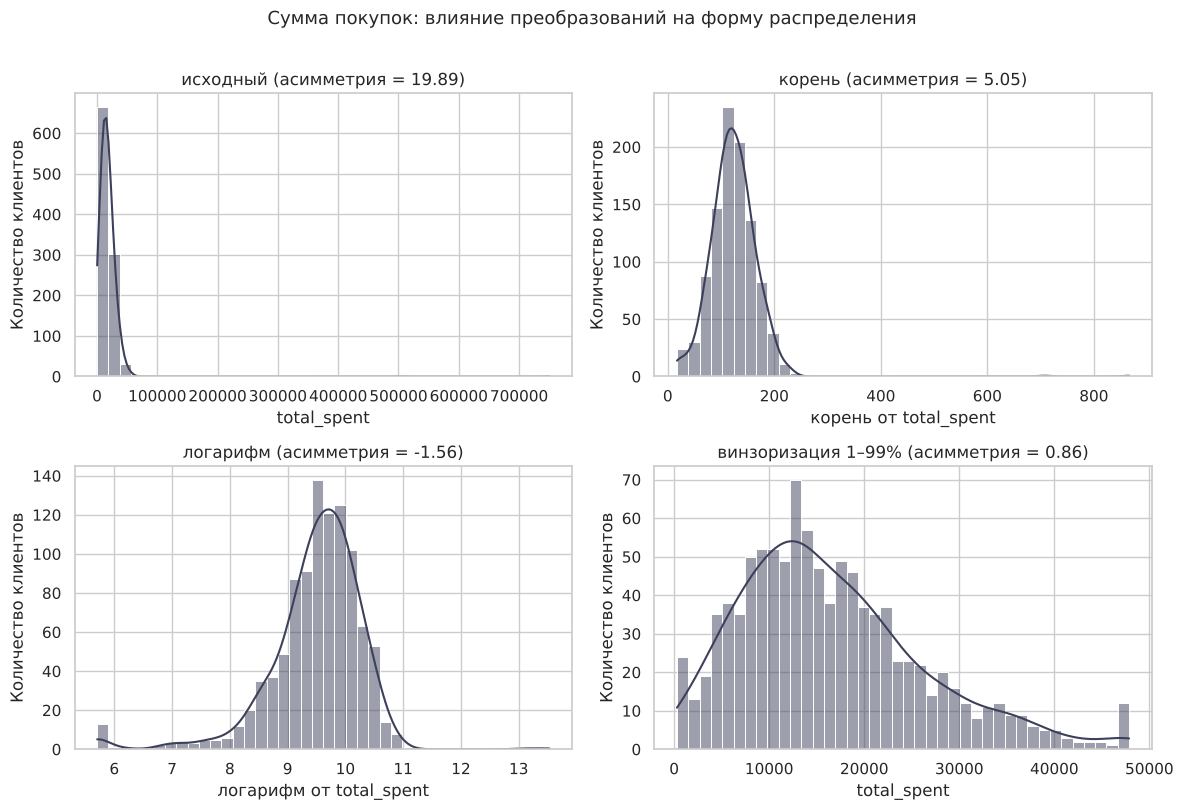

Для счётчика orders_count (асимметрия): исходный 0.40, корень -0.18, логарифм -0.84


In [33]:
y = df_clean["total_spent"].astype(float)
oc_all = df_clean["orders_count"].astype(float)
lo, hi = y.quantile(0.01), y.quantile(0.99)

variants = {
    "исходный": y,
    "корень": np.sqrt(y),
    "логарифм": np.log(y),
    "винзоризация 1–99%": y.clip(lo, hi),
}
rows = []
for name, v in variants.items():
    rows.append({"Вариант": name, "Асимметрия": v.skew(), "Эксцесс": v.kurt(),
                 "Корреляция Пирсона с orders_count": np.corrcoef(oc_all, v)[0, 1],
                 "Макс/медиана": v.max() / v.median()})
display(pd.DataFrame(rows).round(2))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (name, v) in zip(axes.ravel(), variants.items()):
    sns.histplot(v, bins=40, kde=True, ax=ax, color="#3d405b")
    ax.set_title(f"{name} (асимметрия = {v.skew():.2f})")
    ax.set_xlabel("total_spent" if name in ("исходный", "винзоризация 1–99%") else f"{name} от total_spent")
    ax.set_ylabel("Количество клиентов")
plt.suptitle("Сумма покупок: влияние преобразований на форму распределения", y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

print("Для счётчика orders_count (асимметрия):",
      f"исходный {oc_all.skew():.2f}, корень {np.sqrt(oc_all).skew():.2f}, логарифм {np.log(oc_all).skew():.2f}")

### 5.1. Когда что выбирать

- **Логарифм.** Для строго положительных величин с мультипликативной природой и длинным правым хвостом (суммы, цены, доходы), когда значения различаются в десятки раз. Не работает с нулями и отрицательными (тогда `log(1+x)`).
- **Корень.** Для умеренной асимметрии и счётчиков (число заказов), где возможны нули. Сжимает хвост слабее логарифма.
- **Винзоризация.** Когда экстремальные значения — вероятные ошибки или редкие выбросы, удалять строки нельзя, а привычный масштаб (рубли) нужно сохранить. Крайние значения «подрезаются» до заданных перцентилей.

### 5.2. Как подходы влияют на анализ

| | Интерпретируемость | Линейные модели | Визуализация |
| :--- | :--- | :--- | :--- |
| **Логарифм** | ниже: единицы — «лог-рубли»; зато коэффициенты читаются как проценты изменения | уменьшает асимметрию и стабилизирует дисперсию (но при малых значениях может перекосить влево) | растягивает левую часть и сжимает хвост: видна структура основной массы |
| **Корень** | ниже, но проще логарифма | слабее лечит асимметрию, подходит для счётчиков | умеренно сжимает хвост |
| **Винзоризация** | сохраняется: рубли остаются рублями, меняются лишь крайние значения | защищает от влияния одиночных выбросов, но сама по себе форму не исправляет | убирает «палки» и далёкие точки, график читается лучше |

**Что показывает таблица.** На исходных данных асимметрия огромна (≈ 19.9) из-за двух ошибочных значений. Корень снижает её до ≈ 5.1, логарифм — до ≈ −1.6, а винзоризация — до ≈ 0.9 (корреляция с `orders_count` вырастает с 0.21 до 0.67). Логарифм даже «перекручивает» распределение: хвост появляется слева, потому что в данных много малых сумм, включая «заглушки» 300 (для логарифма это сильные отклонения вниз). Для счётчика `orders_count` корень (асимметрия 0.40 → −0.18) работает мягче и аккуратнее логарифма (→ −0.84). В итоге для `total_spent` здесь лучше подходит винзоризация, а логарифм — после отдельной обработки значений-заглушек.

## Задание 6. Средние, которые вводят в заблуждение

Признак: **`total_spent`** (все значения положительные, так что геометрическое среднее определено). Считаем на `df_clean` (с экстремальными значениями) и на `df_eda` (без них).

In [34]:
def three_means(s):
    return {"Арифметическое": s.mean(), "Медиана": s.median(), "Геометрическое": stats.gmean(s), "Гармоническое": stats.hmean(s)}

tbl = pd.DataFrame({
    "с экстремумами (df_clean)": three_means(df_clean["total_spent"].astype(float)),
    "без экстремумов (df_eda)":  three_means(df_eda["total_spent"].astype(float)),
}).round(0)
display(tbl)
print("Асимметрия log(total_spent) без экстремумов:", round(np.log(df_eda["total_spent"].astype(float)).skew(), 2))

,с экстремумами (df_clean),без экстремумов (df_eda)
Арифметическое,17704.0,16487.0
Медиана,14703.0,14673.0
Геометрическое,13203.0,13102.0
Гармоническое,7045.0,7031.0


Асимметрия log(total_spent) без экстремумов: -1.85


### 6.1–6.2. Почему они различаются и что лучше отражает «типичное»

- **Арифметическое среднее** — это сумма, делённая на количество. Оно чувствительно к хвосту: две ошибочные суммы (500 000 и 750 000) поднимают его с 16 487 до 17 704 (+7%), а медиана почти не меняется (14 673 → 14 703).
- **Медиана** — середина упорядоченного ряда. Одиночные выбросы её почти не сдвигают, поэтому она устойчива.
- **Геометрическое среднее** — это `exp(среднее логарифмов)`. Для денежных сумм с логнормальной природой оно имеет смысл («типичный множитель») и менее чувствительно к большим значениям. Но оно возможно только для положительных значений. Здесь оно ниже медианы (≈ 13 200 против ≈ 14 700): у логарифма суммы левый хвост из малых значений, в том числе из «заглушек» 300.
- **Гармоническое среднее** оказывается ещё меньше: оно усиливает влияние маленьких значений (например, 13 значений `300`).

Порядок «гармоническое < геометрическое < арифметическое» выполняется всегда (для положительных значений), а разрыв между ними растёт с разбросом данных. Здесь он велик, потому что данные неоднородны.

**Что лучше отражает «типичное».** **Медиана.** Она устойчива и к выбросам, и к скошенности, а её смысл понятен («половина клиентов тратит меньше»). Геометрическое среднее можно использовать как вторую оценку, если нужна мультипликативная интерпретация, но на него заметно влияют малые значения, включая «заглушки» 300. Арифметическое среднее в этих данных вводит в заблуждение: оно выше медианы на 20% с экстремумами и на 12% без них (правый хвост крупных клиентов), поэтому как «средний клиент» оно завышает типичную сумму.

# 9. Визуализация как инструмент мышления

## Задание 7. Неправильная диаграмма

Берём визуализацию из п. 4.2: **столбчатую диаграмму числа клиентов по категориям товара** (`product_category`). Покажем, что существуют типы диаграмм, которые подходят для этих данных хуже.

Доли категорий: от 18.7% до 21.4%, разброс 2.7 п.п.
Разница в угле сектора между крупнейшей и мельчайшей категориями: 9.7° из 360°


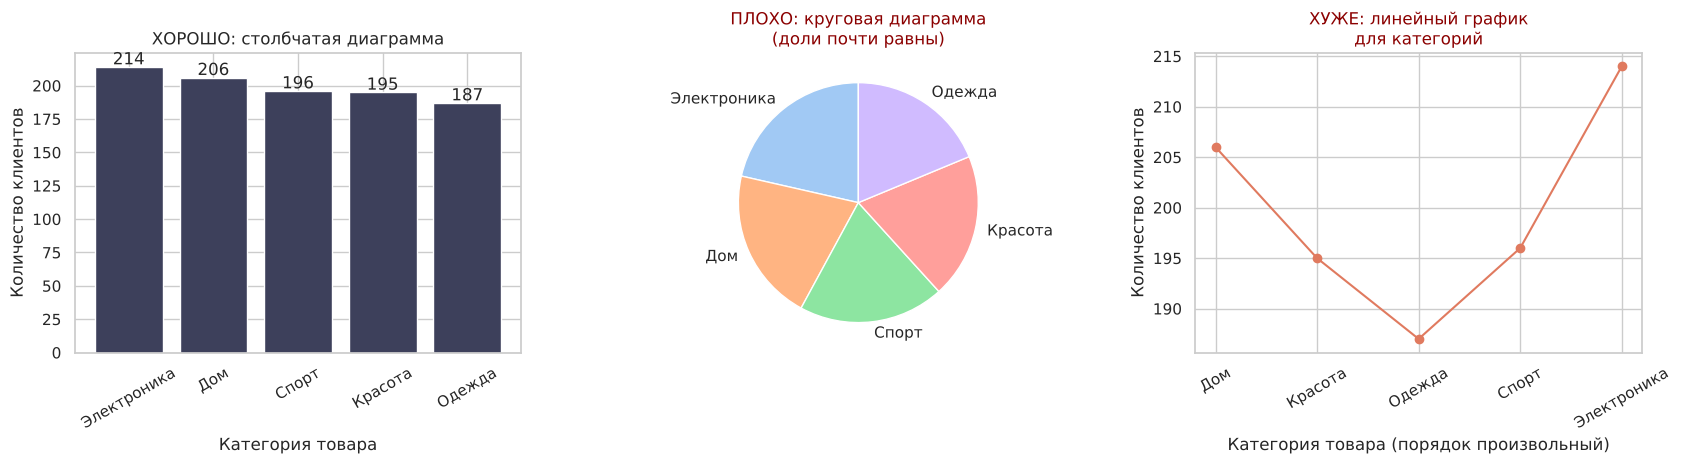

In [35]:
pc = df_eda["product_category"].value_counts()
share = pc / pc.sum()
spread = (share.max() - share.min()) * 100
print(f"Доли категорий: от {share.min()*100:.1f}% до {share.max()*100:.1f}%, разброс {spread:.1f} п.п.")
print(f"Разница в угле сектора между крупнейшей и мельчайшей категориями: {spread*3.6:.1f}° из 360°")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

axes[0].bar(pc.index.astype(str), pc.values, color="#3d405b")
for i, v in enumerate(pc.values):
    axes[0].text(i, v + 2, str(v), ha="center")
axes[0].set_title("ХОРОШО: столбчатая диаграмма")
axes[0].set_xlabel("Категория товара"); axes[0].set_ylabel("Количество клиентов")
axes[0].tick_params(axis="x", rotation=30)

axes[1].pie(pc.values, labels=pc.index.astype(str), startangle=90, colors=sns.color_palette("pastel"))
axes[1].set_title("ПЛОХО: круговая диаграмма\n(доли почти равны)", color="darkred")

axes[2].plot(pc.sort_index().index.astype(str), pc.sort_index().values, marker="o", color="#e07a5f")
axes[2].set_title("ХУЖЕ: линейный график\nдля категорий", color="darkred")
axes[2].set_xlabel("Категория товара (порядок произвольный)"); axes[2].set_ylabel("Количество клиентов")
axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

### 7.1. Доказательство
Для данных с несколькими почти равными категориями (доли 18.7–21.4%) хуже всего подходят:

- **Круговая диаграмма.** Различие между самой большой и самой маленькой долями — 2.7 п.п., то есть около 10° из 360°. Человек плохо сравнивает углы и площади секторов, поэтому на круге все категории выглядят одинаково, а на столбцах разница в 27 клиентов видна сразу. Доказательство: круг почти неразличим при сравнении долей, а числа на столбцах читаются точно.
- **Линейный график.** Для номинальной шкалы порядок категорий произволен, а линия между точками предполагает непрерывность.

### 7.2. Какую информацию искажает и какой неверный вывод возможен

- **Круговая диаграмма** скрывает, что категории распределены почти равномерно, и не позволяет упорядочить их по размеру. Зритель может решить, что «Электроника» и «Одежда» занимают одинаковую долю (хотя разница около 27 клиентов), либо, наоборот, ошибочно «увидеть» лидера по цвету.
- **Линейный график** создаёт ложную непрерывность: наклон отрезков выглядит как «тенденция» между категориями. Зритель может сделать вывод, что «категории растут/убывают слева направо», хотя порядок выбран по алфавиту и ничего не значит. Ось Y здесь ещё и начинается с 185, поэтому разница между 187 и 214 клиентами выглядит как «провал» и «взлёт».

## Задание 8. Одна и та же информация — разные графики

Пара признаков: **`product_category`** (категориальный) и **`total_spent`** (числовой). Два типа визуализации: **boxplot** и **столбчатая диаграмма средних с 95% доверительным интервалом**.

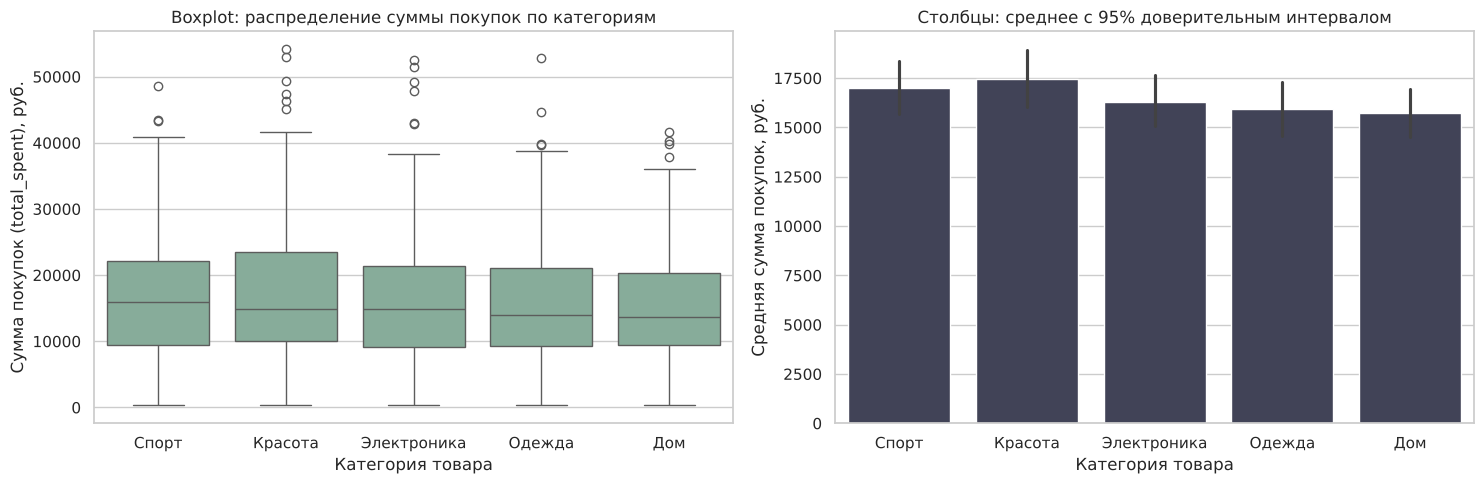

Критерий Краскела–Уоллиса: H = 4.04, p = 0.401
                     mean   median      std
product_category                           
Красота           17470.0  14927.0  10219.0
Спорт             16981.0  15891.0  10034.0
Электроника       16308.0  14896.0   9867.0
Одежда            15952.0  13954.0   9559.0
Дом               15757.0  13692.0   9010.0


In [36]:
order = df_eda.groupby("product_category", observed=True)["total_spent"].median().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df_eda, x="product_category", y="total_spent", order=order, color="#81b29a", ax=axes[0])
axes[0].set_title("Boxplot: распределение суммы покупок по категориям")
axes[0].set_xlabel("Категория товара"); axes[0].set_ylabel("Сумма покупок (total_spent), руб.")

sns.barplot(data=df_eda, x="product_category", y="total_spent", order=order, estimator="mean",
            errorbar=("ci", 95), color="#3d405b", ax=axes[1])
axes[1].set_title("Столбцы: среднее с 95% доверительным интервалом")
axes[1].set_xlabel("Категория товара"); axes[1].set_ylabel("Средняя сумма покупок, руб.")
plt.tight_layout()
plt.show()

groups = [g["total_spent"].values for _, g in df_eda.groupby("product_category", observed=True)]
h, p = stats.kruskal(*groups)
print(f"Критерий Краскела–Уоллиса: H = {h:.2f}, p = {p:.3f}")
print(df_eda.groupby("product_category", observed=True)["total_spent"].agg(["mean", "median", "std"]).round(0).sort_values("mean", ascending=False).to_string())

### 8.1–8.2. Что подчёркивает каждый график

- **Boxplot** показывает **распределение внутри групп**: медиану, межквартильный размах, асимметрию и выбросы. Видно, что «ящики» сильно перекрываются: разброс внутри каждой категории (стандартное отклонение ≈ 10 тысяч) намного больше различий между категориями (средние различаются максимум на 1.7 тысячи).
- **Столбцы со средним и доверительным интервалом** подчёркивают **различия средних** и неопределённость их оценки. Удобно быстро ранжировать категории и увидеть, перекрываются ли интервалы.

**Какие гипотезы легче заметить в одном, но сложно в другом.**

- Гипотезу об **асимметрии и тяжёлом хвосте** внутри категории (например, что в «Спорте» больше крупных клиентов) легко заметить на boxplot (длинные усы, точки-выбросы), а на столбцах она скрывается: среднее «схлопывает» форму распределения.
- Гипотезу о **лидере по среднему** проще проверить на столбцах: интервалы показывают, различимы ли средние. По среднему лидирует «Красота» (≈ 17 470), а по медиане — «Спорт» (≈ 15 891), и именно boxplot (медианы) и столбцы (средние) дают разное ранжирование. Из-за правого хвоста средние и медианы не совпадают.
- Опасность столбцов: если обрезать ось Y не от нуля, небольшие различия выглядят огромными, а boxplot такого не допускает.

Критерий Краскела–Уоллиса не находит значимых различий между категориями (p > 0.05), и график это подтверждает: доверительные интервалы сильно перекрываются. Значит, гипотеза «категория товара влияет на сумму покупок» в этих данных не подтверждается (H = 4.04, p = 0.40).

# Итоги

| № | Проблема | Масштаб | Решение |
| :-: | :--- | :--- | :--- |
| 1 | Пропуски | `customer_income` 6.1%, `age` 4.9%, `average_check` 4.1%, `city` 3.0% | импутация; `average_check` — пересчёт из `total_spent/orders_count` |
| 2 | Полные дубликаты | 3 строки (`C0051`–`C0053`) | удалены |
| 3 | Невозможный возраст | 3 значения (−5, 0, 150) | заменены на пропуск |
| 4 | «Грязные» категории | `city` (Москва в 3 написаниях), `payment_method` (`' карта '`) | нормализованы |
| 5 | Экстремальные суммы | `total_spent` = 500 000 и 750 000 | проверить у источника, исключить из обучения |
| 6 | Нереалистичный средний чек | 45 000, 60 000, 85 000 | заменить на пропуск и восстановить |
| 7 | Значения-«заглушки» на границах | `300` (13), `500` (8), `25000` (11) | выяснить смысл, при необходимости пометить |
| 8 | Нарушение `total_spent ≈ orders_count × average_check` | около 50 строк | проверить, использовать как признак аномальности |
| 9 | Искусственно ровные даты и распределения | `order_date`, категории | учесть при интерпретации; синтетика |

Подробное описание, риски и приоритеты — в `report/quality_report.md`.